In [2]:
from pathlib import Path
import sys
import numpy as np
from pycorr import TwoPointCorrelationFunction

sys.path.insert(0, "/global/homes/m/mawais/quijote_tools")
import readfof

base = Path("/pscratch/sd/m/mawais/Quijote")
catalog_base = base / "Halos/FoF/fiducial"
outdir = base / "BAO/Test0/pre_recon"

mock_ids = [1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004]
z = 0.5
omega_m = 0.3175
boxsize = 1000.0
min_particles = 20
s_edges = np.arange(0.0, 205.0, 5.0)
mu_edges = np.linspace(-1.0, 1.0, 201)
h_z_over_h = 100.0 * np.sqrt(
    omega_m * (1.0 + z)**3 + (1.0 - omega_m)
)

# Confirm that these are the settings saved for mock 0.
pilot = outdir / "fiducial_0_snap003_xi_rsd.npz"
with np.load(pilot) as saved:
    assert int(saved["n_halos"]) == 309740
    assert np.array_equal(saved["s_edges"], s_edges)
    assert np.array_equal(saved["mu_edges"], mu_edges)
    assert saved["xi0"].shape == (40,)
    assert saved["xi2"].shape == (40,)
    assert saved["xi4"].shape == (40,)
print("Mock 0 saved measurement and binning checked.")

# Confirm all nine input catalogue parts are present before computing.
for mock_id in mock_ids:
    part = catalog_base / str(mock_id) / "groups_003/group_tab_003.0"
    if not part.is_file() or part.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty: {part}")

for mock_id in mock_ids:
    output = outdir / f"fiducial_{mock_id}_snap003_xi_rsd.npz"

    # A completed run can be resumed without overwriting valid results.
    if output.exists():
        with np.load(output) as saved:
            valid = (
                np.array_equal(saved["s_edges"], s_edges)
                and np.array_equal(saved["mu_edges"], mu_edges)
                and all(
                    saved[key].shape == (40,)
                    and np.all(np.isfinite(saved[key]))
                    for key in ("xi0", "xi2", "xi4")
                )
            )
        if not valid:
            raise RuntimeError(f"Existing output needs inspection: {output}")
        print(f"Mock {mock_id}: existing output checked; skipping.")
        continue

    snapdir = catalog_base / str(mock_id)
    fof = readfof.FoF_catalog(
        str(snapdir), 3,
        long_ids=False, swap=False, SFR=False, read_IDs=False
    )

    keep = np.asarray(fof.GroupLen) >= min_particles
    positions = np.asarray(fof.GroupPos[keep], dtype=np.float64) / 1000.0
    raw_vz = np.asarray(fof.GroupVel[keep, 2], dtype=np.float64)

    # Redshift-space displacement along z, in Mpc/h.
    dz = raw_vz * (1.0 + z)**2 / h_z_over_h
    positions[:, 2] = (positions[:, 2] + dz) % boxsize

    result = TwoPointCorrelationFunction(
        "smu",
        (s_edges, mu_edges),
        data_positions1=[positions[:, i] for i in range(3)],
        position_type="xyz",
        boxsize=boxsize,
        los="z",
        engine="corrfunc",
        nthreads=4,
    )
    s, xi = result.get_corr(return_sep=True, ells=(0, 2, 4))
    s, xi = np.asarray(s), np.asarray(xi)

    if s.shape != (40,) or xi.shape != (3, 40):
        raise RuntimeError(f"Unexpected arrays for mock {mock_id}: {s.shape}, {xi.shape}")
    if not np.all(np.isfinite(xi)):
        raise RuntimeError(f"Non-finite multipole values for mock {mock_id}")

    np.savez_compressed(
        output,
        s=s,
        xi0=xi[0],
        xi2=xi[1],
        xi4=xi[2],
        s_edges=s_edges,
        mu_edges=mu_edges,
        n_halos=int(keep.sum()),
        boxsize=boxsize,
        redshift=z,
        min_particles=min_particles,
    )
    print(f"Mock {mock_id}: {keep.sum()} halos; saved {output.name}")

print("Finished measuring the nine additional pre-reconstruction 2PCFs.")

Mock 0 saved measurement and binning checked.
Mock 1: 310442 halos; saved fiducial_1_snap003_xi_rsd.npz
Mock 10: 309061 halos; saved fiducial_10_snap003_xi_rsd.npz
Mock 100: 308982 halos; saved fiducial_100_snap003_xi_rsd.npz
Mock 1000: 308644 halos; saved fiducial_1000_snap003_xi_rsd.npz
Mock 10000: 310037 halos; saved fiducial_10000_snap003_xi_rsd.npz
Mock 10001: 308926 halos; saved fiducial_10001_snap003_xi_rsd.npz
Mock 10002: 308529 halos; saved fiducial_10002_snap003_xi_rsd.npz
Mock 10003: 310242 halos; saved fiducial_10003_snap003_xi_rsd.npz
Mock 10004: 308812 halos; saved fiducial_10004_snap003_xi_rsd.npz
Finished measuring the nine additional pre-reconstruction 2PCFs.


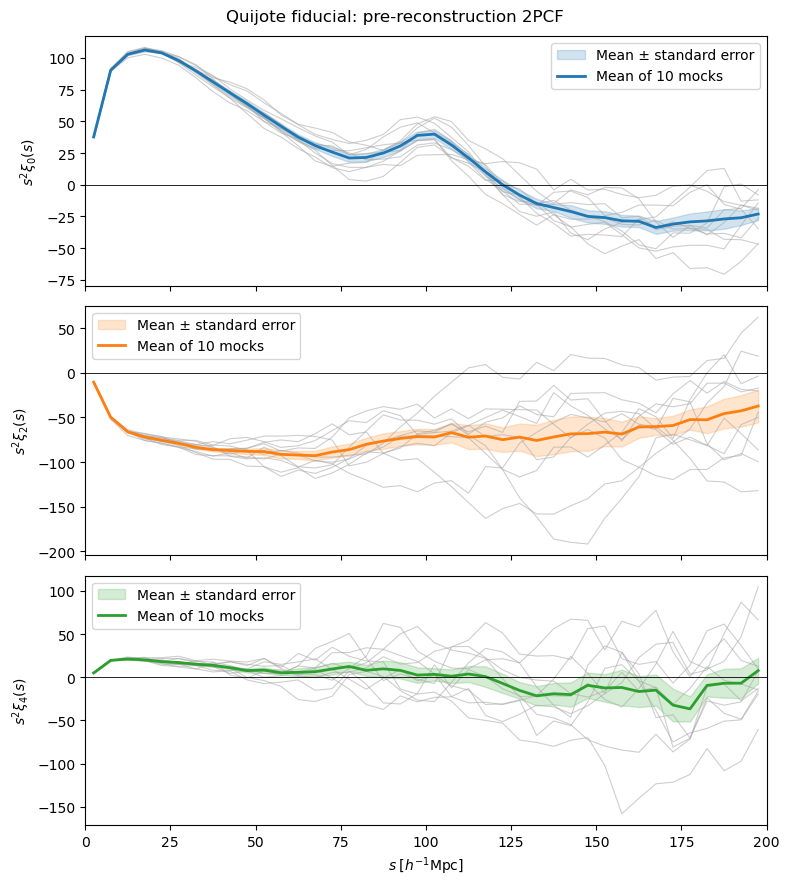

Measurements: (10, 3, 40)
Mean: (3, 40)
Mocks: [0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004]
Halo counts: [309740, 310442, 309061, 308982, 308644, 310037, 308926, 308529, 310242, 308812]
Mean number density [(h/Mpc)^3]: 0.0003093415
Saved mean: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_10mock_mean_snap003_xi_rsd.npz
Saved plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_10mock_mean_snap003_xi_rsd.png


In [4]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

outdir = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
mock_ids = [0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004]
ells = (0, 2, 4)

xi_each = []
s_pairavg_each = []
halo_counts = []

s_edges_expected = np.arange(0.0, 205.0, 5.0)
mu_edges_expected = np.linspace(-1.0, 1.0, 201)

for mock_id in mock_ids:
    path = outdir / f"fiducial_{mock_id}_snap003_xi_rsd.npz"

    with np.load(path) as data:
        if not np.array_equal(data["s_edges"], s_edges_expected):
            raise RuntimeError(f"Separation bins differ: mock {mock_id}")
        if not np.array_equal(data["mu_edges"], mu_edges_expected):
            raise RuntimeError(f"Mu bins differ: mock {mock_id}")
        if float(data["boxsize"]) != 1000.0:
            raise RuntimeError(f"Box size differs: mock {mock_id}")
        if float(data["redshift"]) != 0.5:
            raise RuntimeError(f"Redshift differs: mock {mock_id}")
        if int(data["min_particles"]) != 20:
            raise RuntimeError(f"Halo cut differs: mock {mock_id}")

        s_pairavg = np.asarray(data["s"], dtype=float)
        xi = np.stack(
            [np.asarray(data[f"xi{ell}"], dtype=float) for ell in ells]
        )

        if s_pairavg.shape != (40,) or xi.shape != (3, 40):
            raise RuntimeError(f"Unexpected array shape: mock {mock_id}")
        if not np.all(np.isfinite(s_pairavg)) or not np.all(np.isfinite(xi)):
            raise RuntimeError(f"Non-finite measurement: mock {mock_id}")
        if not np.all(
            (s_pairavg >= s_edges_expected[:-1])
            & (s_pairavg <= s_edges_expected[1:])
        ):
            raise RuntimeError(f"Returned separations outside bins: mock {mock_id}")

        halo_counts.append(int(data["n_halos"]))
        s_pairavg_each.append(s_pairavg)
        xi_each.append(xi)

xi_each = np.stack(xi_each)                 # (10, 3, 40)
s_pairavg_each = np.stack(s_pairavg_each)   # (10, 40)
xi_mean = xi_each.mean(axis=0)              # (3, 40)
xi_scatter = xi_each.std(axis=0, ddof=1)    # scatter among mocks
xi_mean_error = xi_scatter / np.sqrt(len(mock_ids))

# A common, exactly 5 Mpc/h-spaced coordinate for the mean.
s_centres = 0.5 * (s_edges_expected[:-1] + s_edges_expected[1:])
nbar_mean = np.mean(halo_counts) / 1000.0**3

mean_path = outdir / "fiducial_10mock_mean_snap003_xi_rsd.npz"
np.savez_compressed(
    mean_path,
    s=s_centres,
    s_edges=s_edges_expected,
    mu_edges=mu_edges_expected,
    xi0=xi_mean[0],
    xi2=xi_mean[1],
    xi4=xi_mean[2],
    xi_each=xi_each,
    xi_scatter=xi_scatter,
    xi_mean_error=xi_mean_error,
    s_pairavg_each=s_pairavg_each,
    mock_ids=np.asarray(mock_ids),
    n_halos_each=np.asarray(halo_counts),
    number_density_mean=nbar_mean,
    n_mocks=len(mock_ids),
    boxsize=1000.0,
    redshift=0.5,
    min_particles=20,
)

fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
colors = ("tab:blue", "tab:orange", "tab:green")

for j, (ax, ell, color) in enumerate(zip(axes, ells, colors)):
    for i in range(len(mock_ids)):
        ax.plot(s_centres, s_centres**2 * xi_each[i, j],
                color="0.65", alpha=0.55, lw=0.8)

    y = s_centres**2 * xi_mean[j]
    error = s_centres**2 * xi_mean_error[j]
    ax.fill_between(s_centres, y - error, y + error,
                    color=color, alpha=0.20, label="Mean ± standard error")
    ax.plot(s_centres, y, color=color, lw=2, label="Mean of 10 mocks")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_ylabel(rf"$s^2\xi_{{{ell}}}(s)$")
    ax.legend(loc="best")

axes[-1].set_xlabel(r"$s\;[h^{-1}\mathrm{Mpc}]$")
axes[-1].set_xlim(0, 200)
fig.suptitle("Quijote fiducial: pre-reconstruction 2PCF")
fig.tight_layout()

plot_path = outdir / "fiducial_10mock_mean_snap003_xi_rsd.png"
fig.savefig(plot_path, dpi=180)
plt.show()

print("Measurements:", xi_each.shape)
print("Mean:", xi_mean.shape)
print("Mocks:", mock_ids)
print("Halo counts:", halo_counts)
print("Mean number density [(h/Mpc)^3]:", nbar_mean)
print("Saved mean:", mean_path)
print("Saved plot:", plot_path)

## Step 2 — Analytical covariance for the mean of ten mocks

We measured the pre-reconstruction redshift-space multipoles
\(\xi_0,\xi_2,\xi_4\) separately for ten Quijote fiducial realizations,
then averaged each separation bin. Before generating the covariance,
we reload the individual measurements and verify their mean against
the saved ten-mock data vector.

We use the same Quijote fiducial cosmology and CAMB-normalized
\(A_s\) as in the successful mock-0 notebook. BeXiCov calibrates its
clustering model to the **ten-mock mean** over
\(10\leq s\leq200\,h^{-1}\mathrm{Mpc}\).

The covariance required for a fit to this mean has the scaling of ten
independent \(1000\,h^{-1}\mathrm{Mpc}\) boxes. We supply their effective
volume, \(10(1000\,h^{-1}\mathrm{Mpc})^3\), and the mean **single-box**
halo number density. We check the resulting full \(120\times120\)
covariance and its \(60\times60\) BAO-fit submatrix before saving.

Node: nid200057


/global/homes/m/mawais/convo/src/convo/__init__.py:25: UserWarning: [!] Attention user: as of version 2.99.6, 'convo.e2e' (alias of 'convo.end_to_end.e2e') will ONLY return the mixing matrix, not the parameters like previous versions. Do beware!
Sorry for the inconvenience, Jacopo :)
  warnings.warn(


Mean verified against ten individual measurements.
Halo counts: [309740, 310442, 309061, 308982, 308644, 310037, 308926, 308529, 310242, 308812]
Number density: 0.0003093415
A_s: 2.135361938993391e-09
Effective volume [(Mpc/h)^3]: 10000000000.0
Generating ten-mock mean covariance...
fit-range [10, 200]
considering  4  polynomials
generating theoretial covariance ...
sigma rec th 0.0
rec check 
kh for P_k_mu_models 0.0001 99.99999999999996
sigmav 6.500546658709468
noFog
k gaussian in 0.0001 10.0
Computing Bessels functions...


/global/homes/m/mawais/BeXiCov/BeXiCov/Models.py:172: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  sigma_v_2 = quad( lambda x : interp_pk(np.exp(x)) * np.exp(x), np.log(1.e-4), np.log(1.e2))[0] / (3. * np.pi**2)


Done!
Computing tabulated sigma squared...
Done!
testing fiducial model for theoretical covariance...
rec check 
kh for P_k_mu_models 0.0001 99.99999999999996
sigmav 6.500546658709468
noFog


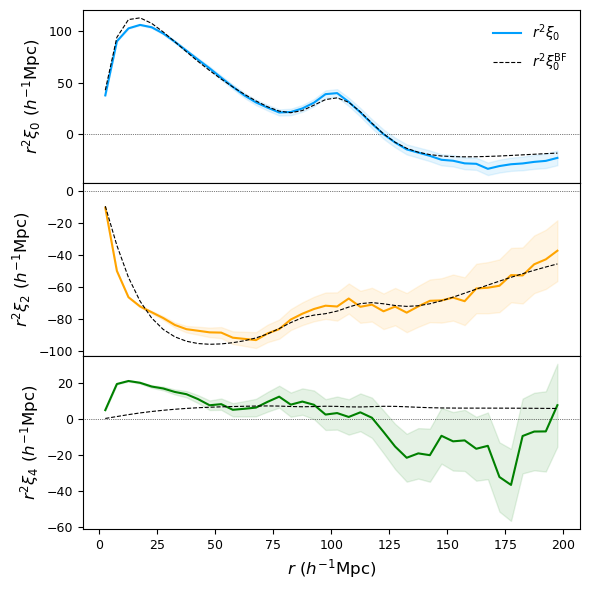

performing best fit 1st iteration ...
shape subcov (114, 114)
Best-fit parameters:
({'alpha_par': 1, 'alpha_perp': 1, 'bias': np.float64(1.9304456453691143), 'f': np.float64(0.3198508906163703), 'Sigma_par': np.float64(6.978966532593736), 'Sigma_perp': np.float64(5.97937940998619), 'Sigma_s': np.float64(0.024655027263397116), 'Sigma_rec': 0}, {'b0-2': np.float64(-0.6943419338155383), 'b0-1': np.float64(4.497830619681409), 'b00': np.float64(-9.546222182523527), 'b01': np.float64(6.284903941550566), 'b02': np.float64(0.032683365807678125), 'b2-2': np.float64(-0.7974206991300017), 'b2-1': np.float64(4.16308451107492), 'b20': np.float64(-5.518681454896249), 'b21': np.float64(1.411817107979985), 'b22': np.float64(-4.855078534266108), 'b4-2': np.float64(0.4278724523851977), 'b4-1': np.float64(-1.2513253345189783), 'b40': np.float64(1.388125040369897), 'b41': np.float64(-3.094854138942809), 'b42': np.float64(2.6192510525220576)})
Parameter errors:
[ 0.13395754  0.31837048  1.63106009  1.21680

In [1]:
import socket
import sys
from pathlib import Path

import numpy as np

host = socket.gethostname()
print("Node:", host)
if "login" in host.lower():
    raise RuntimeError("Run BeXiCov on a NERSC CPU compute node.")

home = Path.home()
for directory in (
    home / "convo" / "src",
    home / "CosmoSampler",
    home / "BAOFit",
    home / "BeXiCov" / "GaussianCovariance",
    home / "BeXiCov",
):
    if directory.is_dir() and str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

# The installed BeXiCov version still calls np.trapz.
if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid

import BeXiCov.Models as Models
from BeXiCov.Covariance import BestFitCovariance

expected_models = (home / "BeXiCov" / "BeXiCov" / "Models.py").resolve()
if Path(Models.__file__).resolve() != expected_models:
    raise RuntimeError(f"Unexpected BeXiCov import: {Models.__file__}")

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
mean_path = base / "fiducial_10mock_mean_snap003_xi_rsd.npz"
cov_path = base / "fiducial_10mock_mean_snap003_bexicov_prerec.npz"

if cov_path.exists():
    raise FileExistsError(f"Inspect the existing result before rerunning: {cov_path}")

expected_ids = np.array(
    [0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004]
)

with np.load(mean_path, allow_pickle=False) as data:
    edges = np.asarray(data["s_edges"], dtype=float)
    s = 0.5 * (edges[:-1] + edges[1:])
    xi_mean = np.stack(
        [np.asarray(data[f"xi{ell}"], dtype=float) for ell in (0, 2, 4)]
    )
    mock_ids = np.asarray(data["mock_ids"], dtype=int)
    nbar_saved = float(np.asarray(data["number_density_mean"]).item())

assert np.array_equal(edges, np.arange(0.0, 205.0, 5.0))
assert np.array_equal(mock_ids, expected_ids)
assert xi_mean.shape == (3, 40)
assert np.isfinite(xi_mean).all()

# Independently check the saved mean using all ten measured files.
measurements = []
halo_counts = []

for mock_id in expected_ids:
    path = base / f"fiducial_{mock_id}_snap003_xi_rsd.npz"
    with np.load(path, allow_pickle=False) as data:
        assert np.array_equal(data["s_edges"], edges), path
        assert np.isclose(float(data["boxsize"]), 1000.0), path
        assert np.isclose(float(data["redshift"]), 0.5), path
        measurements.append(
            np.stack([data["xi0"], data["xi2"], data["xi4"]]).astype(float)
        )
        halo_counts.append(int(data["n_halos"]))

measurements = np.stack(measurements)
halo_counts = np.asarray(halo_counts)

assert measurements.shape == (10, 3, 40)
assert np.isfinite(measurements).all()
np.testing.assert_allclose(
    xi_mean, measurements.mean(axis=0), rtol=1e-12, atol=1e-14
)

box_volume = 1000.0**3
nbar = halo_counts.mean() / box_volume
np.testing.assert_allclose(nbar_saved, nbar, rtol=1e-12, atol=0)
assert halo_counts.sum() == 3_093_415

# Exact cosmology setup from the successful Task_0.ipynb covariance cell.
cosmo = Models.DefaultCosmology()
cosmo.update({
    "Omega_m": 0.3175,
    "Omega_b": 0.049,
    "Omega_L": 1.0 - 0.3175,
    "Omega_nu": 0.0,
    "h": 0.6711,
    "ns": 0.9624,
    "As": 2.135361938993391e-9,
    "z": 0.5,
    "bias": 1.94,
    "N_eff": 3.046,
})

# Exact single-redshift sigma8 compatibility correction from Task_0.ipynb.
if not hasattr(Models, "_original_Pk_nowiggle_one_z"):
    Models._original_Pk_nowiggle_one_z = Models.Pk_nowiggle

def _Pk_nowiggle_one_z(k, pk_linear, cosmology, sigma8, T_cmb):
    values = np.asarray(sigma8)
    if values.size != 1:
        raise ValueError(f"Expected one sigma8 value, got {values.shape}")
    scalar = float(values.reshape(-1)[0])
    if not np.isfinite(scalar) or scalar <= 0:
        raise ValueError(f"Invalid sigma8: {scalar}")
    return Models._original_Pk_nowiggle_one_z(
        k, pk_linear, cosmology, scalar, T_cmb
    )

Models.Pk_nowiggle = _Pk_nowiggle_one_z

# Covariance of the MEAN: ten independent boxes, with single-box nbar.
volume_mean = len(expected_ids) * box_volume

print("Mean verified against ten individual measurements.")
print("Halo counts:", halo_counts.tolist())
print("Number density:", nbar)
print("A_s:", cosmo["As"])
print("Effective volume [(Mpc/h)^3]:", volume_mean)
print("Generating ten-mock mean covariance...")

cov_run = BestFitCovariance(
    s=s,
    xi_ell_data=xi_mean,
    volume=volume_mean,
    number_density=nbar,
    cosmo=cosmo,
    space="RedshiftSpace",
    rectype="",                 # Pre-reconstruction
    sigma_rec=0.0,
    ellemax=4,
    NormCov=1,
    fit_range=[10, 200],       # Covariance-model calibration
    Niter=2,
    Use_emu=False,
)
cov_run.run()

C_raw = np.asarray(cov_run.cov_it, dtype=float)
assert C_raw.shape == (120, 120), C_raw.shape
assert np.isfinite(C_raw).all()
assert np.all(np.diag(C_raw) > 0)

relative_asymmetry = (
    np.max(np.abs(C_raw - C_raw.T)) / np.max(np.abs(C_raw))
)
assert relative_asymmetry < 1e-10, relative_asymmetry
C = 0.5 * (C_raw + C_raw.T)

fit_bins = np.flatnonzero((s >= 50.0) & (s < 150.0))
fit_indices = np.concatenate(
    [fit_bins + j * len(s) for j in range(3)]
)
assert len(fit_bins) == 20
assert len(fit_indices) == 60

C_fit = C[np.ix_(fit_indices, fit_indices)]
np.linalg.cholesky(C_fit)
assert np.isfinite(cov_run.best_fit_params).all()

# volume_mean already supplies the factor of ten: do not divide C again.
np.savez_compressed(
    cov_path,
    cov=C,
    s=s,
    ells=np.array([0, 2, 4]),
    mock_ids=expected_ids,
    halo_counts=halo_counts,
    number_density=nbar,
    volume_mean=volume_mean,
    calibration_range=np.array([10.0, 200.0]),
    planned_bao_fit_range=np.array([50.0, 150.0]),
    As=cosmo["As"],
    input_file=str(mean_path),
)

print("Relative asymmetry:", relative_asymmetry)
print("Full covariance:", C.shape)
print("BAO-fit submatrix:", C_fit.shape)
print("Saved covariance:", cov_path)

## Step 3 — Standard pre-reconstruction BAO fit to the ten-mock mean

We fit **one data vector**, the bin-by-bin mean of the ten Quijote
fiducial realizations. The data vector contains \(\xi_0,\xi_2,\xi_4\)
in 20 separation bins per multipole over
\(50\leq s<150\,h^{-1}\mathrm{Mpc}\). Its covariance is the BeXiCov
covariance generated for that same mean.

We retain the mock-0 pilot's pre-reconstruction BAOFit configuration:
redshift space, no reconstruction, a free growth-rate parameter \(f\),
and separate \(\alpha_\parallel\) and \(\alpha_\perp\). This is a
best-fit/chi-squared run using Minuit. We record optimizer validity,
covariance accuracy, and whether any parameter reaches its limit
before interpreting the parameter errors.

The saved plot shows the measured mean, its BeXiCov marginal errors,
and the fitted multipoles within the fitting range.

Fitting mean of mocks: [0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004]
Fit points: 20 bins × 3 multipoles = 60
Starting pre-reconstruction BAO fit...
considering  4  polynomials
fit-range [50.0, 150.0]
running fit...
modelling ...
shape subcov (60, 60)
I MnSeedGenerator Computing seed using NumericalGradient calculator


/global/homes/m/mawais/BAOFit/BAOFit/Templates.py:332: ComplexWarning: Casting complex values to real discards the imaginary part
  xi_elle[i]=(2.*elles[i]+1.)/2.*np.trapz(xi_mup_rp*Ll[:, None], x=mus, axis=0,dx=mus[1]-mus[0])


I MnSeedGenerator Evaluated function and gradient in 7.96328 s
I MnSeedGenerator Initial state: FCN =       918.7212756 Edm =       2587872.134 NCalls =     57
I NegativeG2LineSearch Doing a NegativeG2LineSearch since one of the G2 component is negative
I NegativeG2LineSearch Done after 6.83582 s
I MnSeedGenerator Negative G2 found - new state: 
  Minimum value : 121.4051248
  Edm           : 163.8582712
  Internal parameters:	[                0                0    -0.1025528247    -0.4115168461    -0.2013579208 -5.421010862e-19                0                0                0                0....                 0]	
  Internal gradient  :	[     -204.2980075     -244.1487876      1042.641217     -78.63399871     -15.31902384      39.98841262      386.4804268      793.6511225        1429.5898       447.147878....      -108.8805452]	
  Internal covariance matrix:
[[   0.0022247699              0              0              0              0              0              0              0  

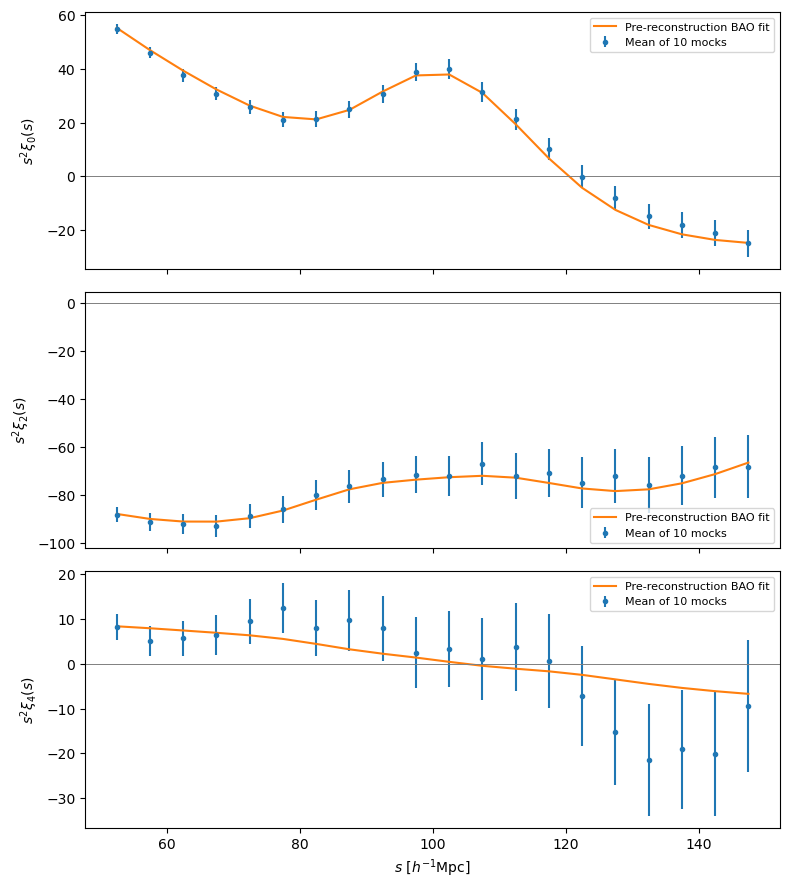

Saved fit: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_10mock_mean_snap003_baofit_prerec.npz
Saved plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_10mock_mean_snap003_baofit_prerec.png


In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid

import BAOFit.Templates as Templates
from BAOFit.Fit import BestFit

home = Path.home()
expected_templates = (home / "BAOFit" / "BAOFit" / "Templates.py").resolve()
if Path(Templates.__file__).resolve() != expected_templates:
    raise RuntimeError(f"Unexpected BAOFit import: {Templates.__file__}")
if "cosmo" not in globals():
    raise RuntimeError("Run code cell 1 in this notebook kernel first.")

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
mean_path = base / "fiducial_10mock_mean_snap003_xi_rsd.npz"
cov_path = base / "fiducial_10mock_mean_snap003_bexicov_prerec.npz"
fit_path = base / "fiducial_10mock_mean_snap003_baofit_prerec.npz"
plot_path = base / "fiducial_10mock_mean_snap003_baofit_prerec.png"

if not cov_path.is_file():
    raise FileNotFoundError(f"Complete the covariance cell first: {cov_path}")
if fit_path.exists() or plot_path.exists():
    raise FileExistsError("Inspect existing ten-mock fit outputs before rerunning.")

with np.load(mean_path, allow_pickle=False) as data:
    edges = np.asarray(data["s_edges"], dtype=float)
    xi = np.stack(
        [np.asarray(data[f"xi{ell}"], dtype=float) for ell in (0, 2, 4)]
    )

with np.load(cov_path, allow_pickle=False) as data:
    s = np.asarray(data["s"], dtype=float)
    C = np.asarray(data["cov"], dtype=float)
    saved_ids = np.asarray(data["mock_ids"], dtype=int)
    volume_saved = float(data["volume_mean"])

assert xi.shape == (3, 40)
assert C.shape == (120, 120)
assert np.array_equal(edges, np.arange(0.0, 205.0, 5.0))
assert np.allclose(s, 0.5 * (edges[:-1] + edges[1:]))
assert len(saved_ids) == 10
assert np.isclose(volume_saved, 10 * 1000.0**3)
assert np.isfinite(xi).all() and np.isfinite(C).all()

fit_mask = (s >= 50.0) & (s < 150.0)
fit_bins = np.flatnonzero(fit_mask)
fit_indices = np.concatenate([fit_bins + j * len(s) for j in range(3)])
assert len(fit_bins) == 20
np.linalg.cholesky(C[np.ix_(fit_indices, fit_indices)])

# Same BAOFit single-redshift sigma8 correction as in Task_0.ipynb.
if not hasattr(Templates, "_original_Pk_nowiggle_one_z"):
    Templates._original_Pk_nowiggle_one_z = Templates.Pk_nowiggle

def _BAOFit_Pk_nowiggle_one_z(k, pk_linear, cosmology, sigma8, T_cmb):
    values = np.asarray(sigma8)
    if values.size != 1:
        raise ValueError(f"Expected one sigma8 value, got {values.shape}")
    scalar = float(values.reshape(-1)[0])
    if not np.isfinite(scalar) or scalar <= 0:
        raise ValueError(f"Invalid sigma8: {scalar}")
    return Templates._original_Pk_nowiggle_one_z(
        k, pk_linear, cosmology, scalar, T_cmb
    )

Templates.Pk_nowiggle = _BAOFit_Pk_nowiggle_one_z

print("Fitting mean of mocks:", saved_ids.tolist())
print("Fit points: 20 bins × 3 multipoles = 60")
print("Starting pre-reconstruction BAO fit...")

bao_fit = BestFit(
    s=s,
    xi_ell_data=xi,
    cov=C,
    cosmo=cosmo,
    space="RedshiftSpace",
    rectype="",
    sigma_rec=0.0,
    ellemax=4,
    fit_range=[50.0, 150.0],
    FoG_opt=False,
    iso_ap=False,
    Use_emu=False,
)
bao_fit.run()
bao_fit.minuit_BF.hesse()

minuit = bao_fit.minuit_BF
physical, broadband = bao_fit.GetParBF()
names = list(bao_fit.initial_guess)
values = np.asarray(minuit.values, dtype=float)
errors = np.asarray(minuit.errors, dtype=float)
uncertainties = dict(zip(names, errors))

print("\n=== TEN-MOCK MEAN BAO FIT ===")
print("Minuit valid:", minuit.fmin.is_valid)
print("Accurate parameter covariance:", minuit.fmin.has_accurate_covar)
print("Parameters at limits:", minuit.fmin.has_parameters_at_limit)
print(f"chi2 / dof: {bao_fit.chi2_raw:.5f} / {bao_fit.ndof}")
for name in ("alpha_par", "alpha_perp", "bias", "f"):
    print(f"{name}: {physical[name]:.6f} +/- {uncertainties[name]:.6f}")

if not minuit.fmin.is_valid or not minuit.fmin.has_accurate_covar:
    raise RuntimeError("Fit diagnostics failed; inspect the printed output.")
if not np.isfinite(values).all():
    raise RuntimeError("Non-finite best-fit parameter.")
if not all(
    np.isfinite(uncertainties[name]) and uncertainties[name] > 0
    for name in ("alpha_par", "alpha_perp")
):
    raise RuntimeError("Invalid BAO dilation-parameter error.")

model = np.asarray(bao_fit.GetModelBF(), dtype=float)
assert model.shape == xi.shape and np.isfinite(model).all()

np.savez_compressed(
    fit_path,
    s=s,
    xi_mean=xi,
    xi_model=model,
    mock_ids=saved_ids,
    parameter_names=np.asarray(names),
    parameter_values=values,
    parameter_errors=errors,
    chi2=float(bao_fit.chi2_raw),
    ndof=int(bao_fit.ndof),
    minuit_valid=bool(minuit.fmin.is_valid),
    accurate_parameter_covariance=bool(minuit.fmin.has_accurate_covar),
    parameters_at_limits=bool(minuit.fmin.has_parameters_at_limit),
    fit_range=np.array([50.0, 150.0]),
    ells=np.array([0, 2, 4]),
    covariance_file=str(cov_path),
)

sigma_xi = np.sqrt(np.diag(C)).reshape(3, 40)
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 9))

for j, ell in enumerate((0, 2, 4)):
    x = s[fit_mask]
    axes[j].errorbar(
        x, x**2 * xi[j, fit_mask],
        yerr=x**2 * sigma_xi[j, fit_mask],
        fmt="o", ms=3, label="Mean of 10 mocks",
    )
    axes[j].plot(
        x, x**2 * model[j, fit_mask],
        color="tab:orange", label="Pre-reconstruction BAO fit",
    )
    axes[j].axhline(0, color="0.5", lw=0.7)
    axes[j].set_ylabel(rf"$s^2\xi_{{{ell}}}(s)$")
    axes[j].legend(fontsize=8)

axes[-1].set_xlabel(r"$s\ [h^{-1}\mathrm{Mpc}]$")
fig.tight_layout()
fig.savefig(plot_path, dpi=180)
plt.show()

print("Saved fit:", fit_path)
print("Saved plot:", plot_path)
if minuit.fmin.has_parameters_at_limit:
    print("CAUTION: A fitted parameter reached its limit; inspect it before interpreting errors.")

Saved fields: ['cov', 's', 'ells', 'mock_ids', 'halo_counts', 'number_density', 'volume_mean', 'calibration_range', 'planned_bao_fit_range', 'As', 'input_file']


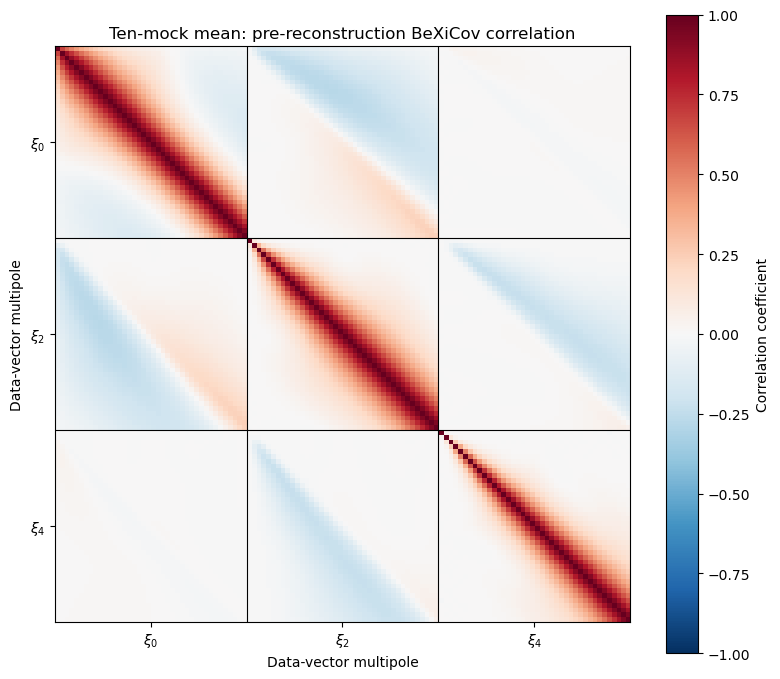

Covariance shape: (120, 120)
Correlation range: -0.2747689909352727 1.0000000000000002
Saved plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_10mock_mean_snap003_bexicov_prerec_correlation.png


In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
cov_path = base / "fiducial_10mock_mean_snap003_bexicov_prerec.npz"
plot_path = base / "fiducial_10mock_mean_snap003_bexicov_prerec_correlation.png"

with np.load(cov_path, allow_pickle=False) as archive:
    print("Saved fields:", archive.files)
    C = np.asarray(archive["cov"], dtype=float)
    s = np.asarray(archive["s"], dtype=float)

assert C.shape == (120, 120), C.shape
assert s.shape == (40,), s.shape
assert np.all(np.isfinite(C))
assert np.all(np.diag(C) > 0)

# Normalize the covariance to correlation coefficients.
sigma = np.sqrt(np.diag(C))
R = C / np.outer(sigma, sigma)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(R, origin="upper", cmap="RdBu_r",
               vmin=-1, vmax=1, interpolation="nearest")
fig.colorbar(im, ax=ax, label="Correlation coefficient")

for boundary in (39.5, 79.5):
    ax.axhline(boundary, color="black", linewidth=0.8)
    ax.axvline(boundary, color="black", linewidth=0.8)

centres = (19.5, 59.5, 99.5)
labels = (r"$\xi_0$", r"$\xi_2$", r"$\xi_4$")
ax.set_xticks(centres, labels)
ax.set_yticks(centres, labels)
ax.set_xlabel("Data-vector multipole")
ax.set_ylabel("Data-vector multipole")
ax.set_title("Ten-mock mean: pre-reconstruction BeXiCov correlation")
fig.tight_layout()

fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Covariance shape:", C.shape)
print("Correlation range:", float(R.min()), float(R.max()))
print("Saved plot:", plot_path)

In [2]:
from pathlib import Path
import ast
import numpy as np

source_file = Path.home() / "BeXiCov" / "BeXiCov" / "Covariance.py"
print("Source file:", source_file)
print("Exists:", source_file.is_file())

if not source_file.is_file():
    raise FileNotFoundError(source_file)

source = source_file.read_text()
lines = source.splitlines()
tree = ast.parse(source)

cls = next(
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
    and node.name == "BestFitCovariance"
)

methods = {
    node.name: node for node in cls.body
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
}

for name in ("run", "test_thcov"):
    print(f"\n=== BestFitCovariance.{name} ===")
    node = methods.get(name)
    if node is None:
        print("Method not found")
    else:
        print("\n".join(lines[node.lineno - 1:node.end_lineno]))

print("\n=== Other relevant methods ===")
print([
    name for name in methods
    if any(word in name.lower()
           for word in ("fit", "model", "plot", "test", "cov"))
])

obj = globals().get("cov_run")
print("\nCompleted cov_run in this kernel:", obj is not None)

if obj is not None:
    print("\n=== Relevant object attributes ===")
    for name, value in vars(obj).items():
        if any(word in name.lower()
               for word in ("xi", "fit", "model", "cov", "param")):
            if isinstance(value, np.ndarray):
                print(f"{name}: array shape {value.shape}")
            else:
                print(f"{name}: {type(value).__name__}")

Source file: /global/homes/m/mawais/BeXiCov/BeXiCov/Covariance.py
Exists: True

=== BestFitCovariance.run ===
    def run(self):
    
        #get theoretical covariance
        print('generating theoretial covariance ...')
        self.xy,self.yx,self.covTH= self.GetThCov()
        self.test_thcov()
        #initial guess, can be modified in function
        if self.initial_guess==None:
            initial_guess=self.SetInitialGuess(self.space,self.rectype)
        else: initial_guess=self.initial_guess
        print('performing best fit 1st iteration ...')
        self.best_fit_params,self.param_errors=self.FitMinuit(self.s,self.xi_ell_data, self.xy,self.yx, self.covTH/self.NormCov,self.space,initial_guess,self.fit_range)
        print('construct covariance, 1st iteration...')
        xy,yx,self.cov_it,self.corr_it = self.ConstructCovariance()
        
        for n in range (1,self.Niter):
            print('performing best fit',str(n), 'iteration ...')
            self.best_fit_par

<unknown>:587: SyntaxWarning: invalid escape sequence '\m'
<unknown>:587: SyntaxWarning: invalid escape sequence '\m'
<unknown>:587: SyntaxWarning: invalid escape sequence '\m'
<unknown>:590: SyntaxWarning: invalid escape sequence '\m'
<unknown>:590: SyntaxWarning: invalid escape sequence '\m'
<unknown>:590: SyntaxWarning: invalid escape sequence '\m'
<unknown>:614: SyntaxWarning: invalid escape sequence '\m'
<unknown>:653: SyntaxWarning: invalid escape sequence '\m'
<unknown>:653: SyntaxWarning: invalid escape sequence '\m'
<unknown>:654: SyntaxWarning: invalid escape sequence '\m'
<unknown>:679: SyntaxWarning: invalid escape sequence '\m'
<unknown>:1113: SyntaxWarning: invalid escape sequence '\m'
<unknown>:1113: SyntaxWarning: invalid escape sequence '\m'
<unknown>:1113: SyntaxWarning: invalid escape sequence '\m'
<unknown>:1116: SyntaxWarning: invalid escape sequence '\m'
<unknown>:1116: SyntaxWarning: invalid escape sequence '\m'
<unknown>:1116: SyntaxWarning: invalid escape seque

In [3]:
from pathlib import Path
import ast
import warnings

path = Path.home() / "BeXiCov" / "BeXiCov" / "Covariance.py"
lines = path.read_text().splitlines()

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=SyntaxWarning)
    tree = ast.parse("\n".join(lines))

cls = next(
    node for node in tree.body
    if isinstance(node, ast.ClassDef)
    and node.name == "BestFitCovariance"
)

wanted = {
    "__init__",
    "GetModelBF",
    "GetModel",
    "ConstructCovariance",
    "plotBF",
}
for node in cls.body:
    if isinstance(node, ast.FunctionDef) and node.name in wanted:
        print(f"\n=== {node.name} ===")
        print("\n".join(lines[node.lineno - 1:node.end_lineno]))


=== __init__ ===
    def __init__(self, s, xi_ell_data,volume, number_density, cosmo, space, rectype='',sigma_rec=0., ellemax=2,NormCov=1, fit_range=[10,200], Niter=2, initial_guess=None, Use_emu = False, Skip_bias = True, Emu_path = ''):    
        self.s=s
        self.xi_ell_data = xi_ell_data
        self.volume = volume
        self.number_density = number_density
        self.cosmo = cosmo
        self.space = space
        self.rectype = rectype
        self.NormCov = NormCov
        self.fit_range = fit_range
        self.ellemax = ellemax #adding exadecapole
        self.Niter = Niter
        self.sigma_rec = sigma_rec
        self.initial_guess=initial_guess
        
        print('fit-range',self.fit_range)       
        
         #Load reference power spectrum for templates
        self.kh, self.Pk_l, f, sigma8,T_cmb = Models.Pk_linear(self.cosmo)
        self.Pk_now = Models.Pk_nowiggle(self.kh,self.Pk_l,self.cosmo,sigma8,T_cmb)
        
        self.Skip_bias = Skip_bi

Node: nid200189
Maximum relative imaginary component: 0.0


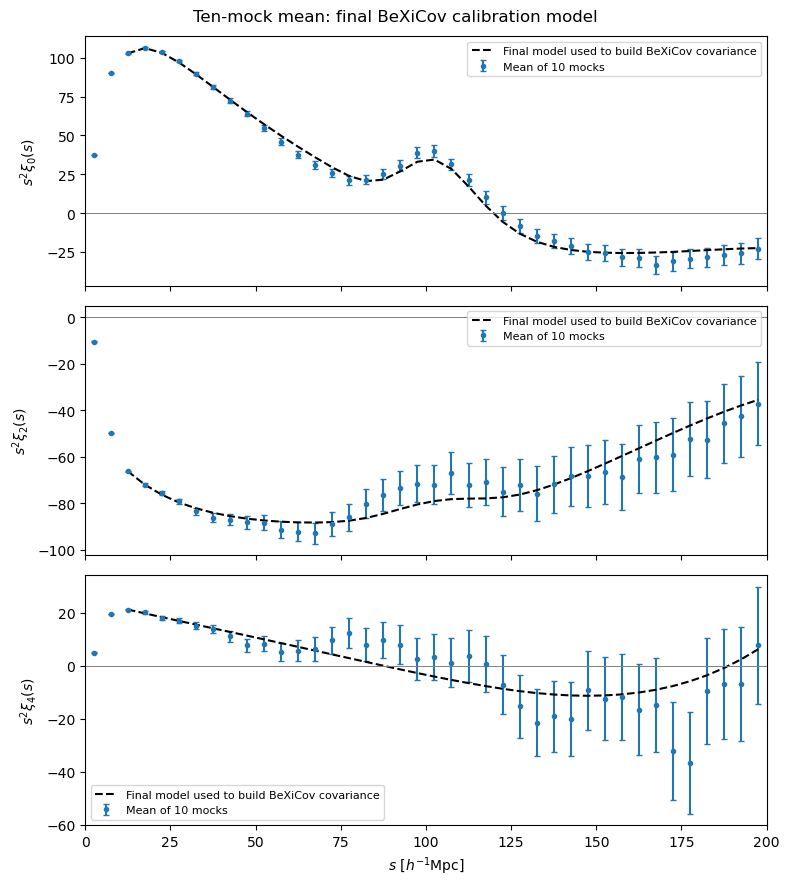

Model shape: (3, 40)
Calibration bins per multipole: 38
Mean number density: 0.0003093415
Saved final-model plot: /pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon/fiducial_10mock_mean_snap003_bexicov_final_model_overlay.png


In [1]:
from pathlib import Path
import sys
import importlib
import socket

import numpy as np
import matplotlib.pyplot as plt

host = socket.gethostname()
print("Node:", host)
if "login" in host.lower():
    raise RuntimeError("Run this model-evaluation cell on a CPU compute node.")

home = Path.home()
repo = home / "BeXiCov"
expected_models = (repo / "BeXiCov" / "Models.py").resolve()
assert expected_models.is_file(), expected_models

# Use the same import paths and NumPy compatibility as the successful run.
for directory in (
    home / "convo" / "src",
    home / "CosmoSampler",
    home / "BAOFit",
    repo / "GaussianCovariance",
    repo,
):
    if directory.is_dir() and str(directory) not in sys.path:
        sys.path.insert(0, str(directory))

if not hasattr(np, "trapz"):
    np.trapz = np.trapezoid

importlib.invalidate_caches()
Models = importlib.import_module("BeXiCov.Models")
assert Path(Models.__file__).resolve() == expected_models, Models.__file__

base = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
cov_path = base / "fiducial_10mock_mean_snap003_bexicov_prerec.npz"
plot_path = base / "fiducial_10mock_mean_snap003_bexicov_final_model_overlay.png"
mock_ids = [0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004]

with np.load(cov_path, allow_pickle=False) as saved:
    s = np.asarray(saved["s"], dtype=float)
    C = np.asarray(saved["cov"], dtype=float)
    As = float(saved["As"])
    volume_mean = float(saved["volume_mean"])
    number_density = float(saved["number_density"])

assert s.shape == (40,)
assert np.allclose(s, 2.5 + 5.0 * np.arange(40))
assert C.shape == (120, 120)
assert np.all(np.isfinite(C))
assert np.all(np.diag(C) > 0)
assert np.isclose(volume_mean, 10 * 1000.0**3)
assert np.isclose(As, 2.135361938993391e-9, rtol=1e-7)

# Recreate the exact ten-mock mean from the already saved measurements.
individual = []
for mock_id in mock_ids:
    path = base / f"fiducial_{mock_id}_snap003_xi_rsd.npz"
    with np.load(path, allow_pickle=False) as saved:
        individual.append(
            np.stack([saved["xi0"], saved["xi2"], saved["xi4"]])
        )

xi_mean = np.mean(np.asarray(individual, dtype=float), axis=0)
assert xi_mean.shape == (3, 40)
assert np.all(np.isfinite(xi_mean))

# Same cosmology and CAMB normalization as the successful covariance run.
cosmo = Models.DefaultCosmology()
cosmo.update({
    "Omega_m": 0.3175,
    "Omega_b": 0.049,
    "Omega_L": 1.0 - 0.3175,
    "Omega_nu": 0.0,
    "h": 0.6711,
    "ns": 0.9624,
    "As": As,
    "z": 0.5,
    "bias": 1.94,
    "N_eff": 3.046,
})

# These are the SECOND BeXiCov fit's printed parameters.
# Its ConstructCovariance() call used this fit to build the saved final C.
physical = {
    "alpha_par": 1.0,
    "alpha_perp": 1.0,
    "bias": 1.9320850694631055,
    "f": 0.3131030354846617,
    "Sigma_par": 6.840858058991921,
    "Sigma_perp": 6.052037010431092,
    "Sigma_s": 0.019893923851875595,
    "Sigma_rec": 0.0,
}
broadband = {
    "b0-2": -0.7051629212851221,
    "b0-1": 4.582950407168428,
    "b00": -9.729732631886314,
    "b01": 6.3967309609612525,
    "b02": 0.02736729528554898,
    "b2-2": -0.7520329315945066,
    "b2-1": 3.93552126599806,
    "b20": -5.082632192827333,
    "b21": 1.0564166498978305,
    "b22": -4.856387113569686,
    "b4-2": 0.4565482682442587,
    "b4-1": -1.360925865434269,
    "b40": 1.5038236751714462,
    "b41": -3.1294551652107656,
    "b42": 2.6244437939382177,
}

# This is precisely the calculation inside GetModelBF(), using the
# second-iteration dictionaries rather than a lost in-memory cov_run.
kh, Pk_l, _, sigma8, T_cmb = Models.Pk_linear(cosmo)
sigma8_values = np.asarray(sigma8)
assert sigma8_values.size == 1
Pk_now = Models.Pk_nowiggle(
    kh, Pk_l, cosmo, float(sigma8_values.reshape(-1)[0]), T_cmb
)

raw_model = (
    np.asarray(
        Models.model_xi_ell(s, physical, kh, Pk_l, Pk_now, ""),
    )
    + np.asarray(Models.BroadBand(s, broadband))
)

# Do not silently discard a significant imaginary component.
real_scale = max(1.0, float(np.max(np.abs(np.real(raw_model)))))
imag_ratio = float(np.max(np.abs(np.imag(raw_model))) / real_scale)
print("Maximum relative imaginary component:", imag_ratio)
assert imag_ratio < 1e-8, "Inspect complex model output before plotting"

xi_model = np.asarray(np.real(raw_model), dtype=float)
assert xi_model.shape == (3, 40), xi_model.shape
assert np.all(np.isfinite(xi_model))

sigma_mean = np.sqrt(np.diag(C)).reshape(3, 40)
calibration_bins = (s >= 10.0) & (s <= 200.0)

fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
for index, ell in enumerate((0, 2, 4)):
    axes[index].errorbar(
        s, s**2 * xi_mean[index],
        yerr=s**2 * sigma_mean[index],
        fmt="o", markersize=3, capsize=2,
        label="Mean of 10 mocks",
    )
    axes[index].plot(
        s[calibration_bins],
        s[calibration_bins]**2 * xi_model[index, calibration_bins],
        "k--", linewidth=1.5,
        label="Final model used to build BeXiCov covariance",
    )
    axes[index].axhline(0, color="0.5", linewidth=0.7)
    axes[index].set_ylabel(rf"$s^2\xi_{{{ell}}}(s)$")
    axes[index].legend(fontsize=8)

axes[-1].set_xlabel(r"$s\ [h^{-1}\mathrm{Mpc}]$")
axes[-1].set_xlim(0, 200)
fig.suptitle("Ten-mock mean: final BeXiCov calibration model")
fig.tight_layout()
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Model shape:", xi_model.shape)
print("Calibration bins per multipole:", calibration_bins.sum())
print("Mean number density:", number_density)
print("Saved final-model plot:", plot_path)

In [2]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from urllib.parse import quote
from html import escape
from IPython.display import HTML, display
import os

home = Path("/global/homes/m/mawais")
plots = Path("/pscratch/sd/m/mawais/Quijote/BAO/Test0/pre_recon")
notebook = home / "Task_10_mocks.ipynb"

names = [
    "fiducial_10mock_mean_snap003_xi_rsd.png",
    "fiducial_10mock_mean_snap003_bexicov_final_model_overlay.png",
    "fiducial_10mock_mean_snap003_bexicov_prerec_correlation.png",
    "fiducial_10mock_mean_snap003_baofit_prerec.png",
]
files = [plots / name for name in names] + [notebook]

for path in files:
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty: {path}")
    if path.suffix == ".png":
        with path.open("rb") as stream:
            if stream.read(8) != b"\x89PNG\r\n\x1a\n":
                raise ValueError(f"Not a valid PNG header: {path}")

archive = home / "Task_10_mocks_review.zip"
with ZipFile(archive, "w", compression=ZIP_DEFLATED) as zf:
    for path in files:
        zf.write(path, arcname=path.name)

with ZipFile(archive) as zf:
    bad_file = zf.testzip()
    if bad_file is not None:
        raise ValueError(f"ZIP integrity check failed: {bad_file}")
    print("Included:", *zf.namelist(), sep="\n  ")

print(f"Archive: {archive} ({archive.stat().st_size:,} bytes)")

# Link for the JupyterHub session shown in your screenshot.
prefix = os.environ.get(
    "JUPYTERHUB_SERVICE_PREFIX",
    "/user/mawais/perlmutter-exclusive-node-cpu/",
)
url = prefix.rstrip("/") + "/files/" + quote(str(archive).lstrip("/"), safe="/")
display(HTML(
    f'<a href="{escape(url, quote=True)}" download="{archive.name}">'
    "Download figures and notebook as one ZIP</a>"
))

Included:
  fiducial_10mock_mean_snap003_xi_rsd.png
  fiducial_10mock_mean_snap003_bexicov_final_model_overlay.png
  fiducial_10mock_mean_snap003_bexicov_prerec_correlation.png
  fiducial_10mock_mean_snap003_baofit_prerec.png
  Task_10_mocks.ipynb
Archive: /global/homes/m/mawais/Task_10_mocks_review.zip (1,096,126 bytes)


## Ten-mock pre-reconstruction BAO pilot: status

We analysed Quijote fiducial FoF halo catalogues at snapshot `003`
(\(z=0.5\)) for ten realizations:
`0, 1, 10, 100, 1000, 10000, 10001, 10002, 10003, 10004`.
The fiducial simulations share a cosmology and vary their initial random
seeds ([Quijote simulation documentation](https://quijote-simulations.readthedocs.io/en/latest/types.html)).

For each realization, we selected halos with at least 20 particles,
placed them in redshift space along the \(z\)-axis, and measured
\(\xi_0,\xi_2,\xi_4\) with periodic boundaries. We used 40 separation
bins spanning \(0\leq s\leq200\,h^{-1}\mathrm{Mpc}\), each
\(5\,h^{-1}\mathrm{Mpc}\) wide. We averaged the ten measurements
bin by bin. The mean array has shape `(3, 40)`, and the mean selected
halo number density is
\(3.093415\times10^{-4}\,(h/\mathrm{Mpc})^3\).

We supplied that mean to BeXiCov for a pre-reconstruction,
redshift-space analytical covariance calculation. The covariance
calibration used \(10\)–\(200\,h^{-1}\mathrm{Mpc}\) (38 bins per
multipole), two internal iterations, and an effective volume of
\(10^{10}\,(h^{-1}\mathrm{Mpc})^3\). The saved covariance has shape
`(120, 120)`; its BAO-fit submatrix has shape `(60, 60)`. The
full-range final BeXiCov model is plotted over the mean measurement.

We then fitted the ten-mock **mean** over
\(50\)–\(150\,h^{-1}\mathrm{Mpc}\), using 20 bins for each of the three
multipoles. The reported BAO fit has
\(\chi^2/\mathrm{dof}=45.252/45\),
\(\alpha_\parallel=1.01779\pm0.02230\), and
\(\alpha_\perp=1.00886\pm0.00793\).

The two internal BeXiCov full-range fits reported reduced
\(\chi^2\) values of 1.891 and 2.141. The final-model overlay shows
remaining multipole residuals; we retain these diagnostics when
reviewing the covariance. The BAO fit and BeXiCov calibration use
different fitting ranges and should be assessed separately.

This notebook fits the ten-mock mean. It does not contain ten
individual BAO fits. The realization-0 velocity/RSD check was a
separate pilot diagnostic.